# 03 · LightGBM on the validation year

The first learned model (DESIGN §7.2), scored on the validation year, 2024-11-01 to 2025-10-31,
against the baselines and REE's forecast. Run `make evaluate` first: this notebook reads
`data/predictions/validation/` and `reports/results/validation.csv`, and refits one model for the
interpretation sections. The metrics are defined in `02_baselines.ipynb`, section 1.

**The model.** One gradient-boosted tree model predicts all 24 hours of the next day; the hour is a
feature. It is trained with squared error on every earlier day, with recent days weighted more
(half-life 2 years), and retrained every 28 days.

**Features** (55, built by `loadforecast.features.build.make_features` from what is known at 10:00 the day before):

| Family | Features |
|---|---|
| Calendar of the target day | hour, weekday, day type, day of year (2 Fourier pairs), holiday intensity, national-holiday flag, bridge intensity, Christmas / August / Holy Week flags, UTC offset |
| Demand lags, same hour | 1 day back (only for hours before 10:00), 2, 7, 14, 21, 28 days back; their 4-week mean; the same mean without holiday weeks; the latest Sunday-or-holiday, Saturday and ordinary working day |
| Calendar of the lagged days | holiday intensity 1, 2, 7 and 14 days back |
| Recent level | last 24 observed hours and the last observed hour, each against a week earlier; this morning against 2 and 8 days back; the last full day against a week earlier |
| Weather at the target hour | temperature, solar radiation, humidity, cloud cover, wind (population-weighted over 10 cities); the day's mean, max and min temperature and mean radiation |
| Weather against the lagged days | temperature and radiation minus their values 2 and 7 days back |
| Thermal inertia | exponentially smoothed daily temperature (weight 0.6 per day), the issue day's temperature |

**Two versions, one model.** The model is always trained on *observed* weather. What changes is the
weather it is given when it forecasts:

- `lgbm_oracle`: tomorrow's observed weather. Not achievable in practice; an upper bound.
- `lgbm_forecast`: the weather forecast archived two days before each hour. The realistic version.

**Uncertainty.** Quantiles are the point forecast plus the empirical quantiles, by hour, of the
model's own out-of-sample errors over the previous 365 days. Section 6 shows why direct quantile
regression was not used.

In [1]:
import json

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loadforecast.config import DATA_DIR, PROCESSED_DIR, ROOT, load_config
from loadforecast.evaluation import metrics, scoring
from loadforecast.evaluation.backtest import prepare_table
from loadforecast.evaluation.dm_test import block_bootstrap_ci, diebold_mariano
from loadforecast.features.build import build_dataset
from loadforecast.models.gbm import LightGBMForecaster, load_model_config, training_dataset
from loadforecast.models.quantiles import quantile_column

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports" / "figures"
SPLIT = "validation"
cfg = load_config("backtest")
TAUS = cfg["quantiles"]
QCOLS = [quantile_column(t) for t in TAUS]
MODELS = ["climatology", "lgbm_oracle", "lgbm_forecast", "ree"]
COLORS = {"climatology": "C2", "lgbm_oracle": "C0", "lgbm_forecast": "C1", "ree": "C3"}

table = pd.read_parquet(PROCESSED_DIR / "hourly.parquet")
meta = json.loads((PROCESSED_DIR / "hourly.meta.json").read_text())
scored = {m: scoring.join_actual(pd.read_parquet(DATA_DIR / "predictions" / SPLIT / f"{m}.parquet"), table)
          for m in MODELS}
results = pd.read_csv(ROOT / "reports" / "results" / f"{SPLIT}.csv", index_col=0)
print(f"{SPLIT}: {len(scored['ree']):,} scored hours on {scored['ree']['local_date'].nunique()} days; dataset {meta['hash']}")

validation: 8,712 scored hours on 363 days; dataset 9de7470fd446c749


## 1. Headline scores

MAE, RMSE, bias and CRPS in MW; MAPE and coverage in %. Skill is relative to `naive_weekly`.

In [2]:
print(results[["MAE", "RMSE", "MAPE", "bias", "CRPS", "cov50", "cov80", "cov90", "width90", "skill_MAE", "skill_CRPS"]]
      .round(3).to_string())

                          MAE     RMSE  MAPE    bias     CRPS  cov50  cov80  cov90  width90  skill_MAE  skill_CRPS
model                                                                                                             
naive_daily          2,442.86 3,358.29  9.08   -2.44 1,390.05  50.33  80.35  89.46 9,940.23      -0.70       -0.54
naive_weekly         1,438.06 2,092.41  5.29   -0.09   903.01  45.37  74.58  85.11 5,448.96       0.00        0.00
climatology_adjusted 1,233.93 1,637.16  4.53  -14.10   695.73  45.78  73.28  84.21 4,276.01       0.14        0.23
climatology          1,221.00 1,617.71  4.47 -153.30   695.70  47.60  74.42  85.04 4,363.36       0.15        0.23
lgbm_forecast          537.99   731.36  1.99  -23.58   315.12  48.20  78.56  88.44 2,112.56       0.63        0.65
lgbm_oracle            523.02   712.99  1.94   29.49   307.65  48.32  78.62  89.10 2,093.24       0.64        0.66
ree                    454.87   640.76  1.67   10.61   270.54  48.13  77.65  87.

### Against REE, and the value of knowing the weather

Differences in daily MAE with a 95% block-bootstrap interval and the Diebold–Mariano p-value.

In [3]:
daily = {m: scoring.daily_losses(scored[m], TAUS) for m in MODELS}
def compare(a, b):
    both = daily[a].add_suffix("_a").join(daily[b].add_suffix("_b")).dropna()
    out = {}
    for loss in ("abs_error", "crps"):
        test = diebold_mariano(both[f"{loss}_a"], both[f"{loss}_b"])
        low, high = block_bootstrap_ci(both[f"{loss}_a"], both[f"{loss}_b"])
        out[loss] = f"{test['mean_diff']:+.0f} MW  [{low:+.0f}, {high:+.0f}]  p = {test['p_value']:.2g}"
    return out
pairs = [("lgbm_forecast", "ree"), ("lgbm_oracle", "ree"), ("lgbm_forecast", "lgbm_oracle"), ("lgbm_forecast", "climatology")]
print(pd.DataFrame({f"{a} minus {b}": compare(a, b) for a, b in pairs}).T.rename(
    columns={"abs_error": "daily MAE", "crps": "daily CRPS"}).to_string())

                                                          daily MAE                          daily CRPS
lgbm_forecast minus ree            +83 MW  [+38, +130]  p = 0.00032      +45 MW  [+13, +76]  p = 0.0048
lgbm_oracle minus ree               +68 MW  [+24, +113]  p = 0.0025        +37 MW  [+6, +68]  p = 0.018
lgbm_forecast minus lgbm_oracle        +15 MW  [+2, +30]  p = 0.034         +7 MW  [+0, +16]  p = 0.057
lgbm_forecast minus climatology  -683 MW  [-847, -557]  p = 1.4e-21  -381 MW  [-505, -285]  p = 3.8e-12


## 2. Where it wins and loses

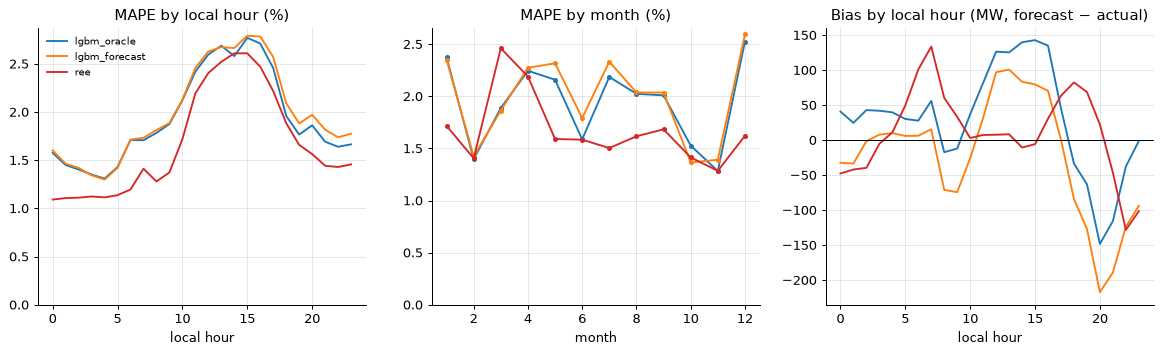

MAPE (%) by kind of day and by temperature:
                      lgbm_oracle  lgbm_forecast  ree  hours  forecast / ree
Christmas period             3.34           3.42 1.85    264            1.85
Holy Week                    2.06           2.19 1.11    144            1.98
Saturday                     1.84           1.93 1.65   1176            1.17
Sunday                       1.98           2.04 1.74   1152            1.18
bridge day                   3.90           4.46 3.17     24            1.41
holiday                      3.19           3.13 2.39    288            1.31
ordinary working day         1.81           1.85 1.63   5664            1.14
cold (<10 °C)                1.92           1.95 1.41   1485            1.38
hot (>22 °C)                 2.05           2.17 1.68   2615            1.29
mild                         1.88           1.89 1.75   4612            1.08


In [4]:
info_cols = ["day_type", "holiday_intensity", "bridge_intensity", "christmas", "holy_week", "temp_obs", "rad_obs"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for m in MODELS[1:]:
    s = scored[m]
    ape = 100 * (s["point"] - s["y"]).abs() / s["y"]
    axes[0].plot(ape.groupby(s["local_hour"]).mean(), color=COLORS[m], label=m)
    axes[1].plot(ape.groupby(s["local_date"].dt.month).mean(), color=COLORS[m], marker=".")
    axes[2].plot((s["point"] - s["y"]).groupby(s["local_hour"]).mean(), color=COLORS[m])
axes[0].set(title="MAPE by local hour (%)", xlabel="local hour", ylim=0)
axes[1].set(title="MAPE by month (%)", xlabel="month", ylim=0)
axes[2].set(title="Bias by local hour (MW, forecast − actual)", xlabel="local hour")
axes[2].axhline(0, color="k", lw=0.8)
axes[0].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "lgbm_errors.png", bbox_inches="tight")
plt.show()

rows = {}
for m in MODELS[1:]:
    s = scored[m].join(table[info_cols])
    ape = 100 * (s["point"] - s["y"]).abs() / s["y"]
    kind = np.select([s["holiday_intensity"] >= 0.3, s["bridge_intensity"] >= 0.5, s["christmas"], s["holy_week"],
                      s["day_type"] == "saturday", s["day_type"] == "sunday_holiday"],
                     ["holiday", "bridge day", "Christmas period", "Holy Week", "Saturday", "Sunday"], "ordinary working day")
    regime = pd.cut(s["temp_obs"], [-20, 10, 22, 50], labels=["cold (<10 °C)", "mild", "hot (>22 °C)"]).astype(str)
    rows[m] = pd.concat([ape.groupby(kind).mean(), ape.groupby(regime).mean()])
by_kind = pd.DataFrame(rows)
by_kind["hours"] = pd.concat([pd.Series(kind).value_counts(), regime.value_counts()])
by_kind["forecast / ree"] = by_kind["lgbm_forecast"] / by_kind["ree"]
print("MAPE (%) by kind of day and by temperature:")
print(by_kind.round(2).to_string())

## 3. Are the uncertainty bands honest?

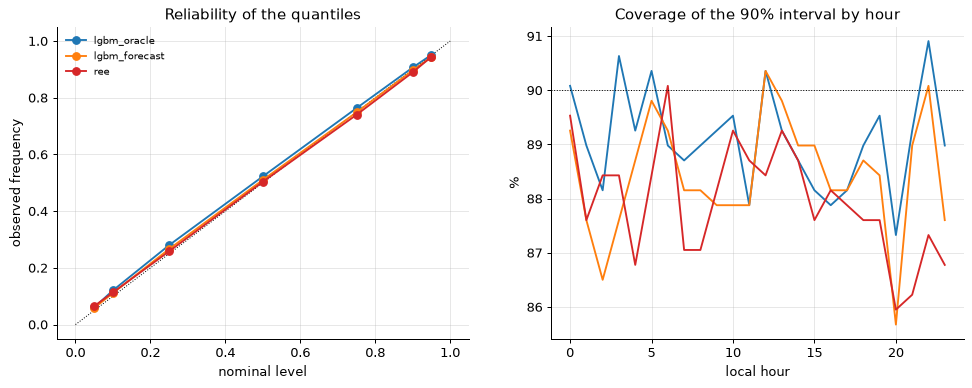

Coverage of the 90% interval by quarter (%):
local_date     2024Q4  2025Q1  2025Q2  2025Q3  2025Q4
lgbm_oracle     90.10   88.70   89.10   86.00   97.70
lgbm_forecast   87.20   89.20   88.30   85.40   98.30
ree             90.30   83.20   88.60   88.10   94.90


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot([0, 1], [0, 1], color="k", lw=0.8, ls=":")
for m in MODELS[1:]:
    s = scored[m].dropna(subset=QCOLS)
    axes[0].plot(TAUS, [(s["y"] <= s[c]).mean() for c in QCOLS], marker="o", color=COLORS[m], label=m)
axes[0].set(xlabel="nominal level", ylabel="observed frequency", title="Reliability of the quantiles")
axes[0].legend(frameon=False, fontsize=8)
cover = {}
for m in MODELS[1:]:
    s = scored[m].dropna(subset=QCOLS)
    inside = (s["y"] >= s["q0.05"]) & (s["y"] <= s["q0.95"])
    cover[m] = 100 * inside.groupby(s["local_hour"]).mean()
    axes[1].plot(cover[m], color=COLORS[m], label=m)
axes[1].axhline(90, color="k", lw=0.8, ls=":")
axes[1].set(xlabel="local hour", ylabel="%", title="Coverage of the 90% interval by hour")
fig.savefig(FIG / "lgbm_calibration.png", bbox_inches="tight")
plt.show()
rows = {}
for m in MODELS[1:]:
    s = scored[m].dropna(subset=QCOLS)
    inside = (s["y"] >= s["q0.05"]) & (s["y"] <= s["q0.95"])
    rows[m] = 100 * inside.groupby(s["local_date"].dt.to_period("Q").astype(str)).mean()
print("Coverage of the 90% interval by quarter (%):")
print(pd.DataFrame(rows).T.round(1).to_string())

## 4. What the forecasts look like

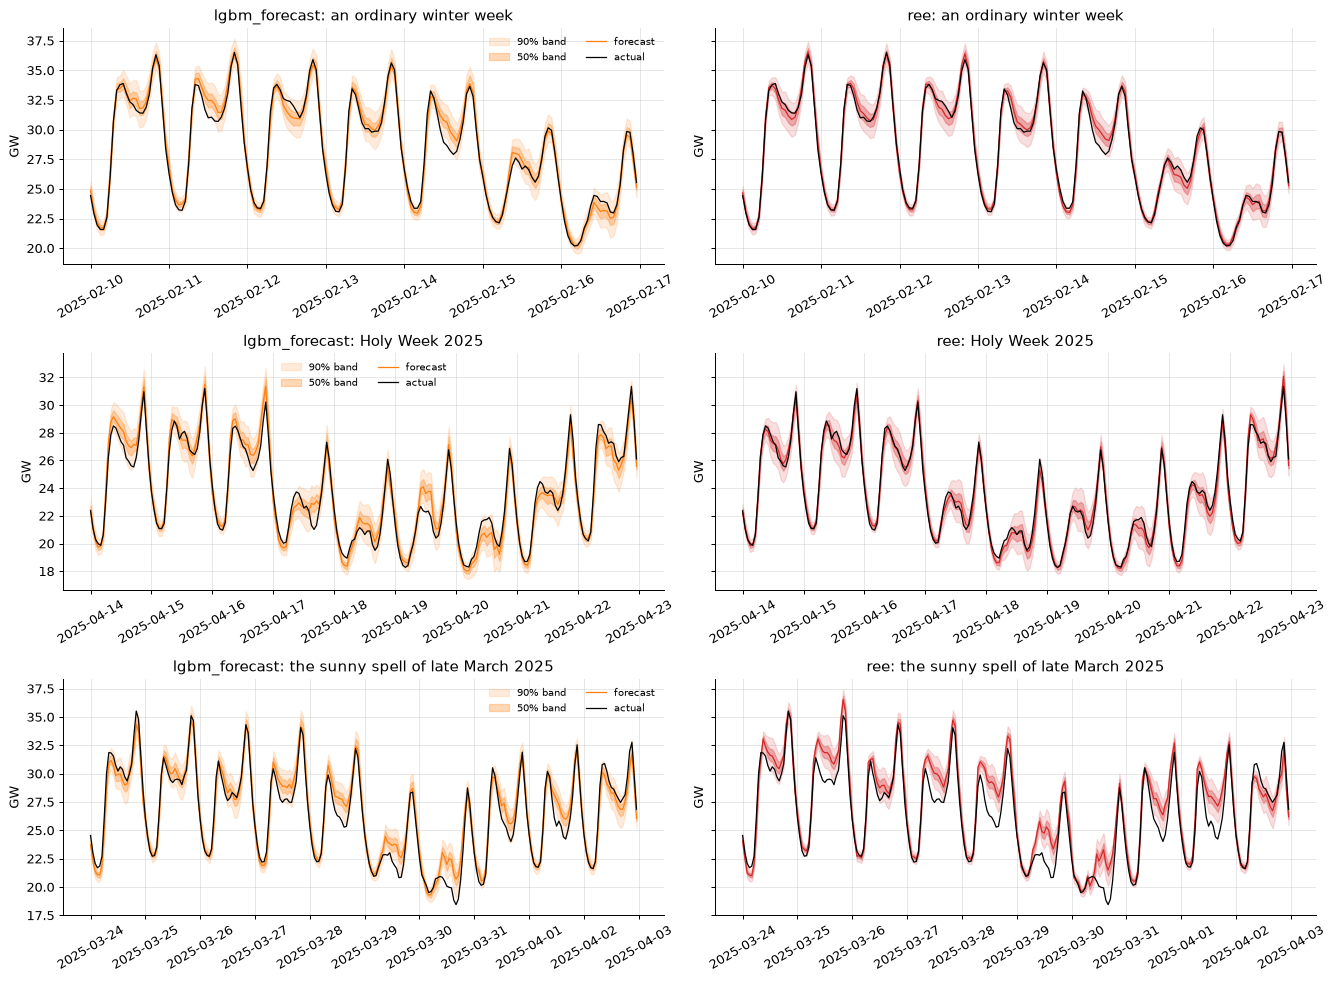

In [6]:
def plot_days(start, end, title, ax_row):
    for ax, m in zip(ax_row, ["lgbm_forecast", "ree"], strict=True):
        s = scored[m]
        s = s[(s["local_date"] >= start) & (s["local_date"] <= end)]
        x = s.index.tz_convert("Europe/Madrid").tz_localize(None)
        ax.fill_between(x, s["q0.05"] / 1000, s["q0.95"] / 1000, color=COLORS[m], alpha=0.15, label="90% band")
        ax.fill_between(x, s["q0.25"] / 1000, s["q0.75"] / 1000, color=COLORS[m], alpha=0.3, label="50% band")
        ax.plot(x, s["point"] / 1000, color=COLORS[m], lw=1, label="forecast")
        ax.plot(x, s["y"] / 1000, color="k", lw=1, label="actual")
        ax.set(title=f"{m}: {title}", ylabel="GW")
        ax.tick_params(axis="x", labelrotation=30)
    ax_row[0].legend(frameon=False, fontsize=8, ncol=2)

fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharey="row")
plot_days("2025-02-10", "2025-02-16", "an ordinary winter week", axes[0])
plot_days("2025-04-14", "2025-04-22", "Holy Week 2025", axes[1])
plot_days("2025-03-24", "2025-04-02", "the sunny spell of late March 2025", axes[2])
fig.tight_layout()
fig.savefig(FIG / "lgbm_examples.png", bbox_inches="tight")
plt.show()

## 5. Best and worst days

In [7]:
day_info = table.groupby("local_date").agg(
    weekday=("weekday", "first"), holiday=("holiday_intensity", "first"), bridge=("bridge_intensity", "first"),
    christmas=("christmas", "first"), holy_week=("holy_week", "first"), temp=("temp_obs", "mean"))
day_info["temp_vs_last_week"] = day_info["temp"].diff(7)
day_info["holiday_week_before"] = day_info["holiday"].shift(7)
day_info["special"] = (day_info["holiday"] >= 0.3) | (day_info["bridge"] >= 0.5) | day_info["christmas"] | day_info["holy_week"]
day_info["weekday"] = pd.Index(day_info.index).day_name().str[:3]
per_day = {}
for m in ("lgbm_forecast", "ree"):
    s = scored[m]
    err = s["point"] - s["y"]
    per_day[m] = pd.DataFrame({"mape": (100 * err.abs() / s["y"]).groupby(s["local_date"]).mean(),
                               "bias_mw": err.groupby(s["local_date"]).mean()})
d = per_day["lgbm_forecast"].join(per_day["ree"]["mape"].rename("ree_mape")).join(day_info)
SHOW = ["mape", "ree_mape", "bias_mw", "weekday", "holiday", "bridge", "christmas", "temp", "temp_vs_last_week"]
print(f"lgbm_forecast: median day {d['mape'].median():.2f}%, mean {d['mape'].mean():.2f}%  (REE: {d['ree_mape'].median():.2f}%, {d['ree_mape'].mean():.2f}%)")
print("\nTen worst days of lgbm_forecast:")
print(d.nlargest(10, "mape")[SHOW].round(2).to_string())
print("\nFive best days:")
print(d.nsmallest(5, "mape")[SHOW].round(2).to_string())
k = len(d) // 10
worst, best = d.nlargest(k, "mape"), d.nsmallest(k, "mape")
def describe(x):
    return pd.Series({"days": len(x), "special days (%)": 100 * x["special"].mean(),
                      "holiday the week before (%)": 100 * (x["holiday_week_before"] >= 0.3).mean(),
                      "mean temp (°C)": x["temp"].mean(), "|temp change vs last week| (°C)": x["temp_vs_last_week"].abs().mean(),
                      "over-forecast days (%)": 100 * (x["bias_mw"] > 0).mean(), "REE MAPE on the same days (%)": x["ree_mape"].mean()})
print("\nWorst and best 10% of days against all days:")
print(pd.DataFrame({"worst 10%": describe(worst), "all days": describe(d), "best 10%": describe(best)}).round(1).to_string())
print(f"\nShare of total error from the worst 10% of days: {100 * worst['mape'].sum() / d['mape'].sum():.0f}%")
print(f"Days on which lgbm_forecast beats REE: {100 * (d['mape'] < d['ree_mape']).mean():.0f}%")
print(f"Rank correlation of daily MAPE with REE: {d['mape'].corr(d['ree_mape'], method='spearman'):.2f}")
ree_worst = set(d.nlargest(k, "ree_mape").index)
print(f"Days in the worst 10% of both: {len(ree_worst & set(worst.index))} of {k}")

lgbm_forecast: median day 1.67%, mean 1.99%  (REE: 1.43%, 1.67%)

Ten worst days of lgbm_forecast:
            mape  ree_mape   bias_mw weekday  holiday  bridge  christmas  temp  temp_vs_last_week
local_date                                                                                       
2024-12-24  9.12      2.44  2,171.07     Tue     0.00    0.00       True  9.25               1.73
2025-07-13  8.22      4.05  1,896.55     Sun     0.00    0.00      False 24.76              -2.59
2024-12-23  6.55      3.51  1,792.52     Mon     0.00    0.00      False  9.83               2.46
2025-01-01  6.43      2.23  1,340.70     Wed     1.00    0.00       True  6.66              -3.73
2024-12-25  6.09      1.90  1,288.03     Wed     1.00    0.00       True 10.39               1.01
2025-01-07  5.75      2.33 -1,725.71     Tue     0.00    0.00      False  9.11               2.65
2025-09-22  5.71      6.33  1,453.70     Mon     0.00    0.00      False 18.75              -5.80
2025-03-30  5.70   

Rank correlation of daily MAPE with REE: 0.37
Days in the worst 10% of both: 13 of 36


## 6. Why the quantiles are not from quantile regression

The design document's default was one LightGBM per quantile, trained with the pinball loss. The
cell below does exactly that (fitted once on data before the validation year, forecast weather at
prediction time) and compares it with the method used.

In [8]:
backtest_table = prepare_table(table)
model_cfg = load_model_config()
dataset = training_dataset(backtest_table, meta["hash"], model_cfg, cfg)
start, end = cfg["splits"][SPLIT]["start"], cfg["splits"][SPLIT]["end"]
features_fc = build_dataset(backtest_table, start, end, issue_time_local=cfg["issue_time_local"],
                            tz=cfg["timezone"], weather="forecast")
FEATURES = [c for c in dataset.columns if c not in ("local_date", "y")]
train = dataset[(dataset["local_date"] < pd.Timestamp(start) - pd.Timedelta(days=1)) & dataset["y"].notna()]
valid = features_fc[features_fc["y"].notna() & ~table["is_masked"].reindex(features_fc.index)]
direct = np.column_stack([
    lgb.train({**model_cfg["params"], "objective": "quantile", "alpha": tau},
              lgb.Dataset(train[FEATURES], train["y"]), model_cfg["num_boost_round"]).predict(valid[FEATURES])
    for tau in TAUS])
direct = np.sort(direct, axis=1)                       # remove quantile crossings
used = scored["lgbm_forecast"].loc[valid.index, QCOLS].to_numpy()
y_valid = valid["y"].to_numpy()
def quantile_summary(q):
    out = {"CRPS (MW)": metrics.crps_from_quantiles(y_valid, q, TAUS).mean()}
    for nominal, lo, hi in [(50, 2, 4), (80, 1, 5), (90, 0, 6)]:
        out[f"coverage {nominal}%"] = 100 * metrics.interval_coverage(y_valid, q[:, lo], q[:, hi])
    out["width 90% (MW)"] = metrics.interval_width(q[:, 0], q[:, 6])
    return out
print(pd.DataFrame({"direct quantile regression": quantile_summary(direct),
                    "point forecast + past errors (used)": quantile_summary(used)}).T.round(1).to_string())
in_sample = np.sort(np.column_stack([
    lgb.train({**model_cfg["params"], "objective": "quantile", "alpha": tau},
              lgb.Dataset(train[FEATURES], train["y"]), model_cfg["num_boost_round"]).predict(train[FEATURES])
    for tau in (0.05, 0.95)]), axis=1)
print(f"\nDirect quantile regression, 90% interval coverage on its own training data: "
      f"{100 * metrics.interval_coverage(train['y'].to_numpy(), in_sample[:, 0], in_sample[:, 1]):.1f}%")

                                     CRPS (MW)  coverage 50%  coverage 80%  coverage 90%  width 90% (MW)
direct quantile regression              371.90         28.30         52.70         68.00        1,574.80
point forecast + past errors (used)     315.10         48.20         78.60         88.40        2,112.60



Direct quantile regression, 90% interval coverage on its own training data: 90.6%


## 7. What the model learned

One model, fitted on all data before the validation year, explained on the validation days with
forecast weather. **SHAP values** split each prediction into a contribution per feature, in MW,
relative to the average prediction; the mean absolute SHAP value is how much a feature moves the
forecast on a typical hour.

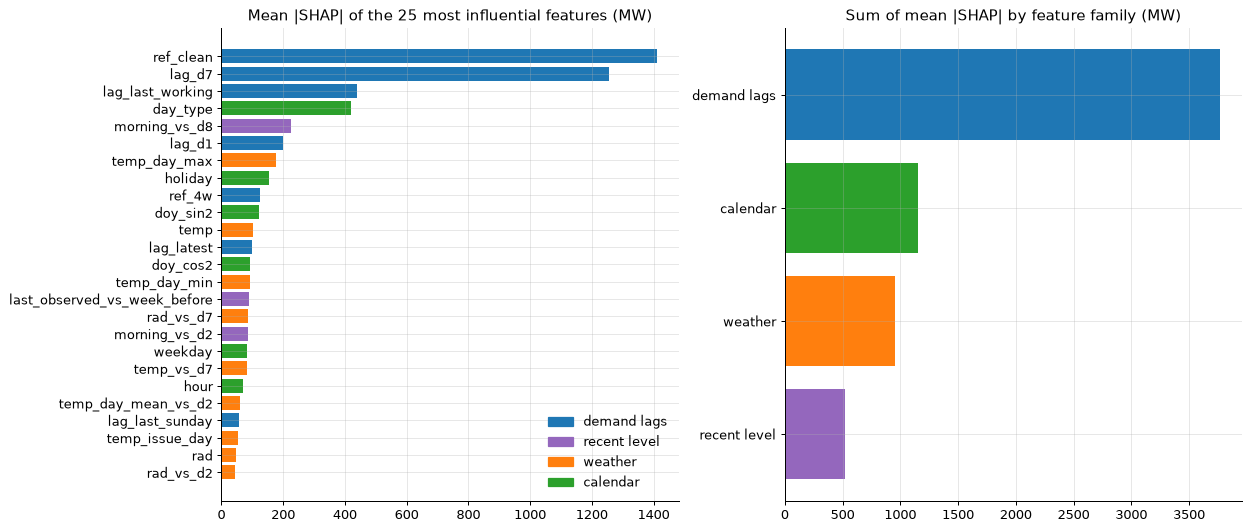

Mean |SHAP| by family (MW): {'recent level': 517.0, 'weather': 957.0, 'calendar': 1151.0, 'demand lags': 3770.0}
Top 12 features (MW): {'ref_clean': 1410.0, 'lag_d7': 1254.0, 'lag_last_working': 440.0, 'day_type': 421.0, 'morning_vs_d8': 224.0, 'lag_d1': 199.0, 'temp_day_max': 178.0, 'holiday': 152.0, 'ref_4w': 125.0, 'doy_sin2': 122.0, 'temp': 103.0, 'lag_latest': 99.0}
5 of 55 features move the forecast by less than 10 MW on average: temp_vs_d2, holiday_national, holy_week, holiday_d14, utc_offset


In [9]:
model = LightGBMForecaster(dataset, "forecast", model_cfg)
data = lgb.Dataset(train[FEATURES], train["y"],
                   weight=0.5 ** (((train["local_date"].max() - train["local_date"]).dt.days / 365.25) / model_cfg["half_life_years"]))
model.booster = lgb.train(model_cfg["params"], data, model_cfg["num_boost_round"])
shap = model.shap_values(valid)
mean_abs = shap.drop(columns="base").abs().mean().sort_values(ascending=False)
FAMILY = {"demand lags": ["lag_", "ref_"], "recent level": ["last", "morning_vs", "day_d2"],
          "weather": ["temp", "rad", "rh", "cloud", "wind"], "calendar": [""]}
def family(name):
    for fam, keys in FAMILY.items():
        if any(name.startswith(k) or (fam == "weather" and k in name) for k in keys):
            return fam
family_of = pd.Series({f: family(f) for f in mean_abs.index})
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top = mean_abs.head(25)[::-1]
palette = {"demand lags": "C0", "recent level": "C4", "weather": "C1", "calendar": "C2"}
axes[0].barh(top.index, top.values, color=[palette[family_of[f]] for f in top.index])
axes[0].set(title="Mean |SHAP| of the 25 most influential features (MW)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), frameon=False)
fam_total = mean_abs.groupby(family_of).sum().sort_values()
axes[1].barh(fam_total.index, fam_total.values, color=[palette[f] for f in fam_total.index])
axes[1].set(title="Sum of mean |SHAP| by feature family (MW)")
fig.tight_layout()
fig.savefig(FIG / "lgbm_shap_importance.png", bbox_inches="tight")
plt.show()
print("Mean |SHAP| by family (MW):", fam_total.round(0).to_dict())
print("Top 12 features (MW):", mean_abs.head(12).round(0).to_dict())
print(f"{(mean_abs < 10).sum()} of {len(mean_abs)} features move the forecast by less than 10 MW on average: "
      f"{', '.join(mean_abs[mean_abs < 10].index)}")

### How single features act

Each point is one validation hour: the feature's value against its SHAP contribution. Weather
features are grouped, because the model spreads one physical effect over several related columns.

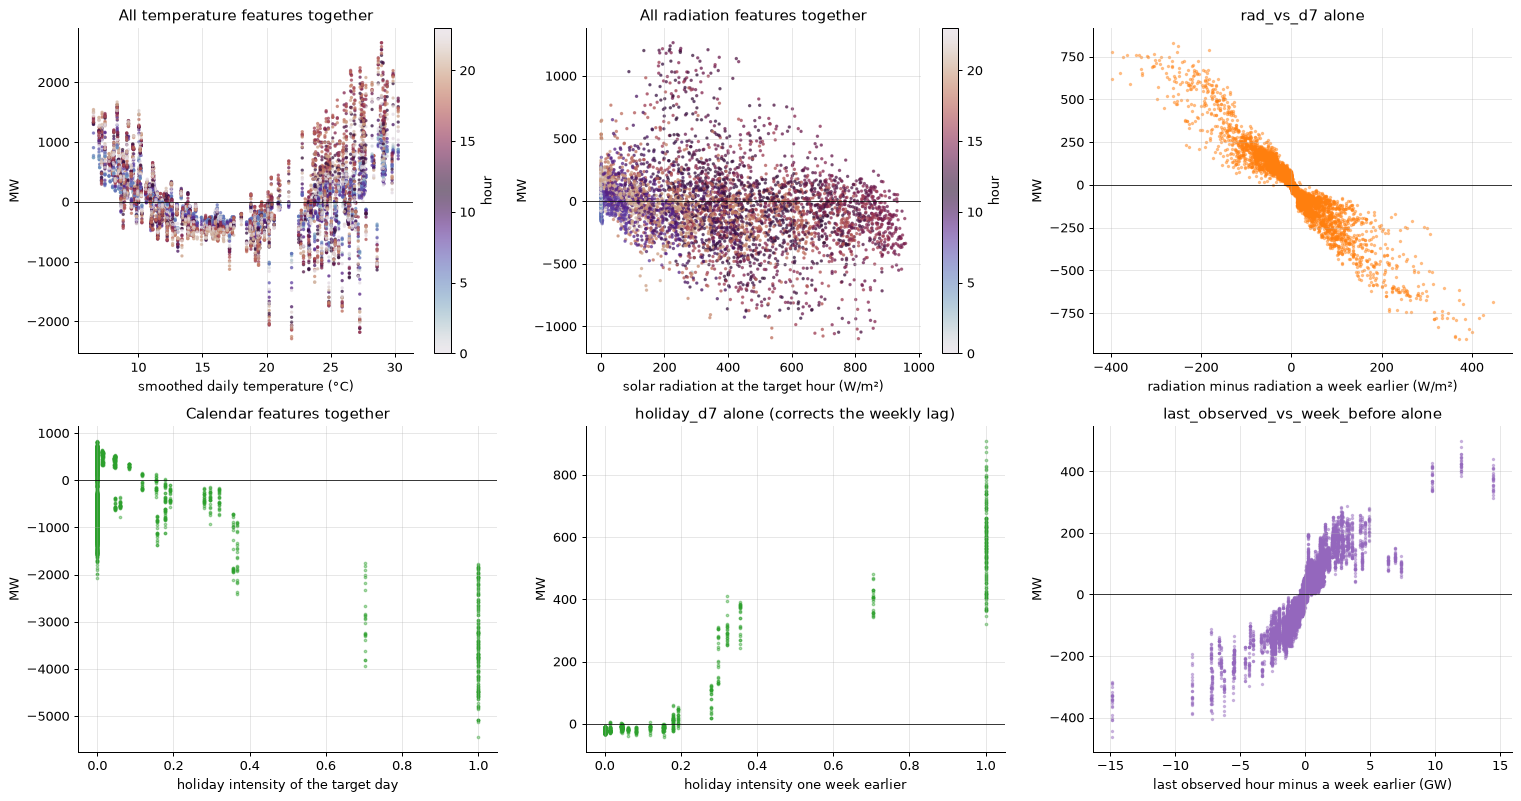

Mean contribution of temperature features by smoothed temperature (MW):
temp_smooth
(0, 8]       804.00
(8, 12]      255.00
(12, 16]    -243.00
(16, 20]    -388.00
(20, 24]    -245.00
(24, 28]     217.00
(28, 40]   1,013.00

Radiation features at 11:00–16:59: mean |contribution| 278 MW; correlation with radiation -0.35
Radiation features at night (00:00–05:59): mean |contribution| 40 MW


In [10]:
temp_group = [c for c in FEATURES if "temp" in c]
rad_group = [c for c in FEATURES if "rad" in c]
hol_group = ["holiday", "holiday_national", "bridge", "christmas", "holy_week", "august", "day_type", "weekday"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sc = axes[0, 0].scatter(valid["temp_smooth"], shap[temp_group].sum(axis=1), c=valid["hour"], s=3, cmap="twilight", alpha=0.6)
axes[0, 0].set(xlabel="smoothed daily temperature (°C)", ylabel="MW", title="All temperature features together")
fig.colorbar(sc, ax=axes[0, 0], label="hour")
sc = axes[0, 1].scatter(valid["rad"], shap[rad_group].sum(axis=1), c=valid["hour"], s=3, cmap="twilight", alpha=0.6)
axes[0, 1].set(xlabel="solar radiation at the target hour (W/m²)", ylabel="MW", title="All radiation features together")
fig.colorbar(sc, ax=axes[0, 1], label="hour")
axes[0, 2].scatter(valid["rad_vs_d7"], shap["rad_vs_d7"], s=3, alpha=0.4, color="C1")
axes[0, 2].set(xlabel="radiation minus radiation a week earlier (W/m²)", ylabel="MW", title="rad_vs_d7 alone")
axes[1, 0].scatter(valid["holiday"], shap[hol_group].sum(axis=1), s=4, alpha=0.4, color="C2")
axes[1, 0].set(xlabel="holiday intensity of the target day", ylabel="MW", title="Calendar features together")
axes[1, 1].scatter(valid["holiday_d7"], shap["holiday_d7"], s=4, alpha=0.4, color="C2")
axes[1, 1].set(xlabel="holiday intensity one week earlier", ylabel="MW", title="holiday_d7 alone (corrects the weekly lag)")
axes[1, 2].scatter(valid["last_observed_vs_week_before"] / 1000, shap["last_observed_vs_week_before"], s=3, alpha=0.4, color="C4")
axes[1, 2].set(xlabel="last observed hour minus a week earlier (GW)", ylabel="MW", title="last_observed_vs_week_before alone")
for ax in axes.ravel():
    ax.axhline(0, color="k", lw=0.6)
fig.tight_layout()
fig.savefig(FIG / "lgbm_shap_dependence.png", bbox_inches="tight", dpi=110)
plt.show()

temp_effect = shap[temp_group].sum(axis=1)
bins = pd.cut(valid["temp_smooth"], [0, 8, 12, 16, 20, 24, 28, 40])
print("Mean contribution of temperature features by smoothed temperature (MW):")
print(temp_effect.groupby(bins, observed=True).mean().round(0).to_string())
rad_effect = shap[rad_group].sum(axis=1)
midday = valid["hour"].between(11, 16)
print(f"\nRadiation features at 11:00–16:59: mean |contribution| {rad_effect[midday].abs().mean():.0f} MW; "
      f"correlation with radiation {np.corrcoef(valid.loc[midday, 'rad'], rad_effect[midday])[0, 1]:.2f}")
print(f"Radiation features at night (00:00–05:59): mean |contribution| {rad_effect[valid['hour'] < 6].abs().mean():.0f} MW")

### Does it handle the sunny days that trip up REE?

In `02_baselines.ipynb` REE's midday error grew with how sunny the day was for the season.

In [11]:
anom = {}
for m in ("lgbm_forecast", "lgbm_oracle", "ree"):
    s = scored[m].join(table[["rad_obs"]])
    mid = s[s["local_hour"].between(11, 16)]
    part = pd.DataFrame({"err": (mid["point"] - mid["y"]).groupby(mid["local_date"]).mean(),
                         "rad": mid.groupby("local_date")["rad_obs"].mean()})
    part["anomaly"] = part["rad"] - part["rad"].rolling(31, center=True, min_periods=10).median()
    sunny = part["anomaly"] > part["anomaly"].quantile(0.9)
    dull = part["anomaly"] < part["anomaly"].quantile(0.1)
    anom[m] = {"correlation of midday error with sunniness": part["err"].corr(part["anomaly"]),
               "midday error, sunniest 10% of days (MW)": part.loc[sunny, "err"].mean(),
               "midday error, dullest 10% of days (MW)": part.loc[dull, "err"].mean(),
               "midday MAE, all days (MW)": (mid["point"] - mid["y"]).abs().mean()}
print(pd.DataFrame(anom).round(2).to_string())
spell = (d.index >= "2025-03-25") & (d.index <= "2025-04-01")
print(f"\n25 March – 1 April 2025: lgbm_forecast MAPE {d.loc[spell, 'mape'].mean():.2f}%, REE {d.loc[spell, 'ree_mape'].mean():.2f}%")

                                            lgbm_forecast  lgbm_oracle      ree
correlation of midday error with sunniness           0.32         0.35     0.54
midday error, sunniest 10% of days (MW)            822.85       870.89 1,241.16
midday error, dullest 10% of days (MW)            -439.07      -449.84  -811.08
midday MAE, all days (MW)                          733.47       721.63   687.96

25 March – 1 April 2025: lgbm_forecast MAPE 2.76%, REE 4.65%


## 8. Conclusions

**Headline.** With realistic weather inputs, LightGBM scores MAPE 1.99%, MAE 538 MW and CRPS
315 MW on the validation year. That is 56% less error than the best baseline (MAE 1,221 MW) and
still behind REE (1.67%, 455 MW, 271 MW): 83 MW worse in daily MAE, with a 95% interval of 38 to
130 MW and p = 0.0003. It beats REE on 40% of days.

**Weather uncertainty is not the bottleneck.** Giving the model tomorrow's observed weather
instead of the forecast improves the MAE by only 15 MW (523 against 538; interval 2 to 30 MW).
Day-ahead weather forecasts are good enough that the gap to REE has to come from somewhere else.

**Where the gap to REE is**

- Smallest around midday (11:00–16:59: 2.67% against 2.47%) and in mild weather (1.89% against 1.75%).
- Largest at night and in the morning (about 1.3 times REE's error), in cold weather (1.95%
  against 1.41%), and above all in special periods: Christmas 3.42% against 1.85%, Holy Week 2.19%
  against 1.11%.
- Six of its ten worst days are in the Christmas period. Special days are 28% of its worst
  tenth of days, against 8% of all days. There are only four or five Christmases in the training data.
- On ordinary working days the gap is 1.85% against 1.63%.

**Where it does better than REE: sunny days.** Its midday error depends less on how sunny the
day is (correlation 0.32 against REE's 0.54; +0.8 GW on the sunniest tenth of days against
+1.2 GW). In the sunny spell of 25 March – 1 April 2025 it scores 2.76% against REE's 4.65%.
Its midday error is still slightly larger than REE's over the whole year (733 against 688 MW).

**Uncertainty.** The bands are close to calibrated: 48.2%, 78.6% and 88.4% for nominal 50, 80
and 90%. By quarter the 90% band covers between 85% and 98%.

**Direct quantile regression failed, and the design default was changed.** One LightGBM per
quantile covers 90.6% of its own training data with its 90% band but only 68.0% of the validation
year: each quantile model fits the training data too closely, so the band is too narrow out of
sample. Its CRPS is 372 MW against 315 MW for the point forecast plus past out-of-sample errors.
Early stopping and stronger regularisation raised the coverage only to 75–77% in exploratory runs.

**What the model learned (SHAP)**

- Demand lags dominate: summed mean |SHAP| of 3,770 MW, against 1,151 MW for the calendar, 957 MW
  for weather and 517 MW for the recent level. The holiday-free 4-week reference and the weekly
  lag are the two strongest features.
- Temperature has the expected U shape: about +800 MW below 8 °C, −390 MW at 16–20 °C and
  +1,000 MW above 28 °C (smoothed daily temperature).
- Radiation lowers the forecast around midday (mean |contribution| 278 MW at 11:00–16:59,
  correlation −0.36 with radiation) and does almost nothing at night (41 MW).
- Five features contribute under 10 MW on average and could be dropped.

**Caveat.** The features, the hyper-parameters and the choice of quantile method were all made
on this validation year, so these scores are somewhat optimistic. The test year is the unbiased check.

### Exploration log

Single-fit experiments on the validation year that led to the final set-up. They are not
reproduced in this notebook; MAPE is for the realistic (forecast-weather) version.

| Step | MAPE (%) | Outcome |
|---|---:|---|
| First feature set, median (pinball) objective | 2.29 | starting point |
| Target as a difference or ratio to the 4-week reference instead of the level | 2.68–2.70 | worse; kept the level |
| Squared-error objective instead of median | 2.20 | kept |
| Smaller trees, more rounds (15 leaves, 2,000 rounds, rate 0.03) | 2.14 | kept |
| + holiday-free reference and "latest Sunday / Saturday / working day" lags | 2.06 | kept; holiday MAPE 3.9 → 3.3% |
| + morning-of-issue-day anomalies | 1.98–2.00 with the above | kept |
| + linear time trend | 1.98 fixed, 2.05 with monthly refits | dropped: unstable when retrained |
| Recency weights, half-life 2 years | 1.96–1.98 | kept (small gain) |
| Monthly or weekly retraining instead of one fit | 1.98–2.00 | no gain; kept for realism |
| Trees with linear leaves | 2.01 | no gain |
| Correction from the model's own recent errors | 1.96–2.04 | no gain |
| City-level degree hours and per-city temperatures (observed weather) | +0.01 to +0.04 | no gain |
| Without any weather feature | 3.01 | weather is worth about 1 percentage point |